# 05 Feature Engineering
Create controlled, business-meaningful, target-independent features.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_raw_data
from src.feature_engineering import engineer_features

data = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
raw_predictors = data.drop(columns=["customerID", "Churn"])
features = engineer_features(raw_predictors)
print("Rows:", len(data))
print("Raw predictor columns:", raw_predictors.shape[1])
print("Engineered predictor columns:", features.shape[1])
features.head()

Rows: 7043
Raw predictor columns: 19
Engineered predictor columns: 38


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,number_of_streaming_services,number_of_support_services,number_of_services,has_dependents,has_partner_or_dependents,senior_single_customer,is_month_to_month,is_one_year_contract,is_two_year_contract,digital_engagement_count
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,0,0,1,0,1,0,1,0,0,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,0,0,3,0,0,0,0,1,0,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,0,0,3,0,0,0,1,0,0,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,0,1,3,0,0,0,0,1,0,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,0,0,1,0,0,0,1,0,0,0


In [2]:
# Feature groups document the business meaning of each engineered feature.
feature_groups = {
    "tenure": ["tenure_months", "tenure_years", "is_new_customer", "is_long_term_customer"],
    "billing": ["avg_monthly_charge", "charge_per_tenure_month", "total_charge_consistency", "high_monthly_charge"],
    "services": ["number_of_services", "number_of_security_services", "number_of_streaming_services", "number_of_support_services", "digital_engagement_count"],
    "profile": ["has_dependents", "has_partner_or_dependents", "senior_single_customer"],
    "contract": ["is_month_to_month", "is_one_year_contract", "is_two_year_contract"],
}
feature_group_inventory = pd.DataFrame([
    {"group": group, "feature": column, "created": column in features}
    for group, columns in feature_groups.items()
    for column in columns
 ])
display(feature_group_inventory)
features[["tenure", "tenure_years", "avg_monthly_charge", "charge_per_tenure_month", "number_of_services", "is_month_to_month"]].describe()

,group,feature,created
0,tenure,tenure_months,True
1,tenure,tenure_years,True
2,tenure,is_new_customer,True
3,tenure,is_long_term_customer,True
4,billing,avg_monthly_charge,True
5,billing,charge_per_tenure_month,True
6,billing,total_charge_consistency,True
7,billing,high_monthly_charge,True
8,services,number_of_services,True
9,services,number_of_security_services,True


,tenure,tenure_years,avg_monthly_charge,charge_per_tenure_month,number_of_services,is_month_to_month
count,7043.000000,7043.000000,7032.000000,7032.000000,7043.000000,7043.000000
mean,32.371149,2.697596,64.799424,8.620087,3.362914,0.550192
std,24.559481,2.046623,30.185891,16.352057,2.062031,0.497510
min,0.000000,0.000000,13.775000,0.268056,0.000000,0.000000
25%,9.000000,0.750000,36.179891,1.277708,1.000000,0.000000
50%,29.000000,2.416667,70.373239,2.147286,3.000000,1.000000
75%,55.000000,4.583333,90.179560,6.611218,5.000000,1.000000
max,72.000000,6.000000,121.400000,102.450000,8.000000,1.000000


,tenure,tenure_months,tenure_years,is_new_customer,is_long_term_customer,tenure_bucket
0,1,1,0.083333,1,0,0-6 months
1,34,34,2.833333,0,0,25-48 months
2,2,2,0.166667,1,0,0-6 months
3,45,45,3.750000,0,0,25-48 months
4,2,2,0.166667,1,0,0-6 months


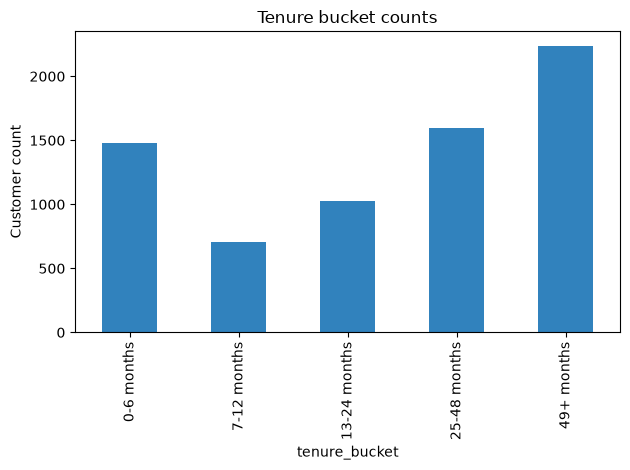

In [3]:
## Tenure features
tenure_features = features[["tenure", "tenure_months", "tenure_years", "is_new_customer", "is_long_term_customer"]].copy()
tenure_features["tenure_bucket"] = pd.cut(
    tenure_features["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49+ months"],
 )
display(tenure_features.head())
tenure_features["tenure_bucket"].value_counts().sort_index().plot.bar(color="#3182bd", title="Tenure bucket counts")
plt.ylabel("Customer count")
plt.tight_layout()
plt.show()

Zero-tenure rows: 11
Missing ratio values for zero-tenure rows: 11


,MonthlyCharges,TotalCharges,tenure,avg_monthly_charge,charge_per_tenure_month,total_charge_consistency,high_monthly_charge,zero_tenure
count,7043.000000,7032.000000,7043.000000,7032.000000,7032.000000,7032.000000,7043.000000,7043
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7032
mean,64.761692,2283.300441,32.371149,64.799424,8.620087,0.153193,0.500355,NaN
std,30.090047,2266.771362,24.559481,30.185891,16.352057,67.255326,0.500035,NaN
min,18.250000,18.800000,0.000000,13.775000,0.268056,-370.850000,0.000000,NaN
25%,35.500000,401.450000,9.000000,36.179891,1.277708,-28.650000,0.000000,NaN
50%,70.350000,1397.475000,29.000000,70.373239,2.147286,0.000000,1.000000,NaN
75%,89.850000,3794.737500,55.000000,90.179560,6.611218,28.700000,1.000000,NaN


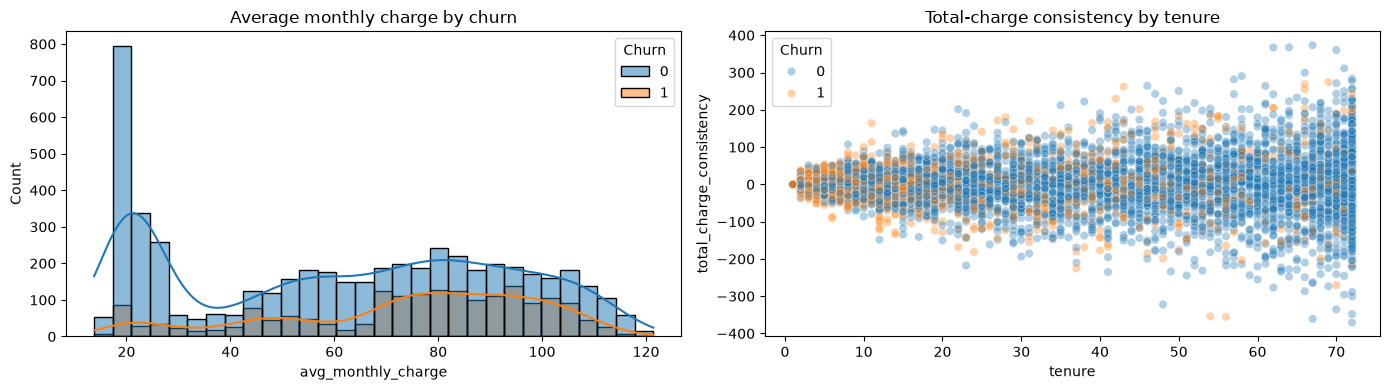

In [4]:
# Billing features and ratio safety checks.
billing_columns = ["MonthlyCharges", "TotalCharges", "tenure", "avg_monthly_charge", "charge_per_tenure_month", "total_charge_consistency", "high_monthly_charge"]
billing_features = features[billing_columns].copy()
billing_features["zero_tenure"] = features["tenure"].eq(0)
print("Zero-tenure rows:", int(billing_features["zero_tenure"].sum()))
print("Missing ratio values for zero-tenure rows:", int(billing_features.loc[billing_features["zero_tenure"], "avg_monthly_charge"].isna().sum()))
display(billing_features.describe(include="all"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=features, x="avg_monthly_charge", hue=data["Churn"], bins=30, kde=True, common_norm=False, ax=axes[0])
axes[0].set_title("Average monthly charge by churn")
sns.scatterplot(data=features.assign(Churn=data["Churn"]), x="tenure", y="total_charge_consistency", hue="Churn", alpha=0.35, ax=axes[1])
axes[1].set_title("Total-charge consistency by tenure")
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max,source_columns
number_of_security_services,7043.0,0.975437,1.016671,0.0,0.0,1.0,2.0,3.0,"OnlineSecurity, OnlineBackup, DeviceProtection"
number_of_streaming_services,7043.0,0.772256,0.852573,0.0,0.0,0.0,2.0,2.0,"StreamingTV, StreamingMovies"
number_of_support_services,7043.0,0.290217,0.453895,0.0,0.0,0.0,1.0,1.0,TechSupport
number_of_services,7043.0,3.362914,2.062031,0.0,1.0,3.0,5.0,8.0,"PhoneService, MultipleLines, OnlineSecurity, O..."
digital_engagement_count,7043.0,2.037910,1.847682,0.0,0.0,2.0,3.0,6.0,"OnlineSecurity, OnlineBackup, DeviceProtection..."


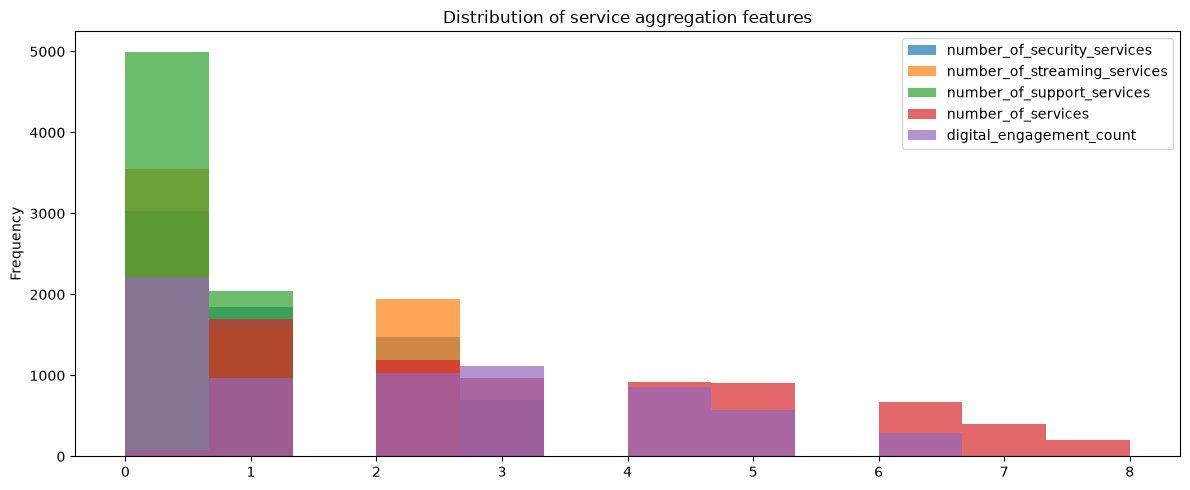

In [5]:
# Service aggregation features use explicit source columns from the problem statement.
service_definitions = {
    "number_of_security_services": ["OnlineSecurity", "OnlineBackup", "DeviceProtection"],
    "number_of_streaming_services": ["StreamingTV", "StreamingMovies"],
    "number_of_support_services": ["TechSupport"],
    "number_of_services": ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"],
    "digital_engagement_count": ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"],
}
service_summary = features[[column for column in service_definitions if column in features]].describe().T
service_summary["source_columns"] = [", ".join(service_definitions[column]) for column in service_summary.index]
display(service_summary)
service_features = [column for column in service_definitions if column in features]
features[service_features].plot(kind="hist", bins=12, alpha=0.7, figsize=(12, 5), title="Distribution of service aggregation features")
plt.tight_layout()
plt.show()

,percentage
has_dependents,29.958824
has_partner_or_dependents,53.428937
senior_single_customer,7.965356
is_month_to_month,55.019168
is_one_year_contract,20.914383
is_two_year_contract,24.066449


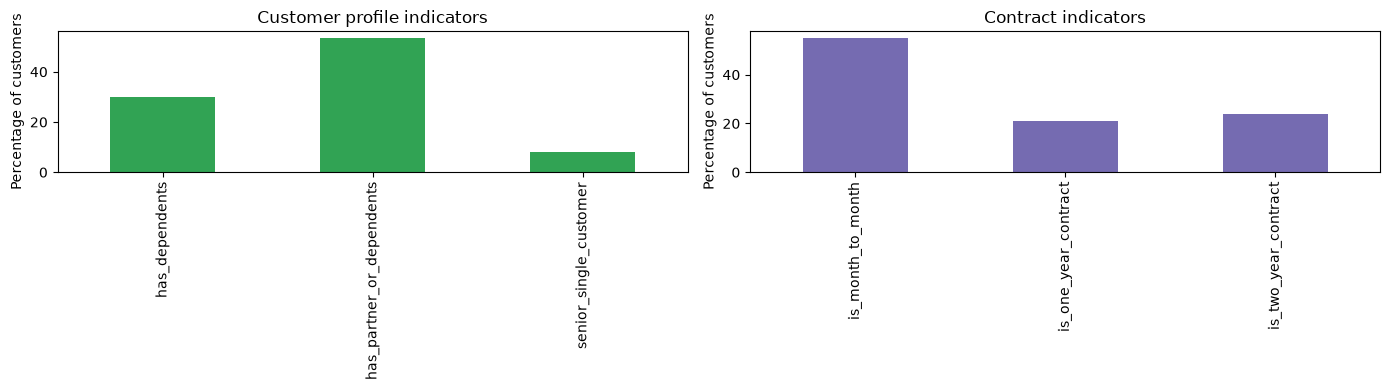

In [6]:
# Customer profile and contract indicators are business-readable binary features.
profile_contract_columns = ["has_dependents", "has_partner_or_dependents", "senior_single_customer", "is_month_to_month", "is_one_year_contract", "is_two_year_contract"]
profile_contract = features[profile_contract_columns].mean().mul(100).rename("percentage").to_frame()
display(profile_contract)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
profile_contract.loc[["has_dependents", "has_partner_or_dependents", "senior_single_customer"]].plot.bar(ax=axes[0], legend=False, color="#31a354", title="Customer profile indicators")
profile_contract.loc[["is_month_to_month", "is_one_year_contract", "is_two_year_contract"]].plot.bar(ax=axes[1], legend=False, color="#756bb1", title="Contract indicators")
axes[0].set_ylabel("Percentage of customers")
axes[1].set_ylabel("Percentage of customers")
plt.tight_layout()
plt.show()

In [7]:
# Evaluate optional transformations without silently replacing the tree-model inputs.
def candidate_transformations(values):
    non_negative = values.clip(lower=0)
    return pd.DataFrame({
        "identity": values,
        "log1p": np.log1p(non_negative),
        "sqrt": np.sqrt(non_negative),
        "square": values ** 2,
        "cube": values ** 3,
    })

transformation_summary = []
for column in ["tenure", "MonthlyCharges", "TotalCharges"]:
    candidates = candidate_transformations(features[column].fillna(features[column].median()))
    for name in candidates.columns:
        transformation_summary.append({"feature": column, "transformation": name, "mean": candidates[name].mean(), "std": candidates[name].std(), "missing": int(candidates[name].isna().sum())})
transformation_table = pd.DataFrame(transformation_summary)
display(transformation_table)
print("These transformations are diagnostic candidates only; tree models do not require automatic transformation." )

,feature,transformation,mean,std,missing
0,tenure,identity,3.237115e+01,2.455948e+01,0
1,tenure,log1p,3.036873e+00,1.155510e+00,0
2,tenure,sqrt,5.114600e+00,2.492568e+00,0
3,tenure,square,1.650974e+03,1.791773e+03,0
4,tenure,cube,9.603577e+04,1.250749e+05,0
5,MonthlyCharges,identity,6.476169e+01,3.009005e+01,0
6,MonthlyCharges,log1p,4.043347e+00,5.802878e-01,0
7,MonthlyCharges,sqrt,7.781184e+00,2.053159e+00,0
8,MonthlyCharges,square,5.099359e+03,3.773908e+03,0
9,MonthlyCharges,cube,4.414930e+05,4.143897e+05,0


These transformations are diagnostic candidates only; tree models do not require automatic transformation.


In [8]:
# Leakage and quality checks: no target or identifier may enter the engineered predictor matrix.
forbidden_columns = {"Churn", "customerID"}
print("Target present in engineered features:", "Churn" in features.columns)
print("Identifier present in engineered features:", "customerID" in features.columns)
print("Infinite values:", int(np.isinf(features.select_dtypes(include="number")).sum().sum()))
print("Rows with any missing engineered values:", int(features.isna().any(axis=1).sum()))
missing_summary = features.isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing_summary["missing_pct"] = missing_summary["missing_count"] / len(features) * 100
display(missing_summary[missing_summary["missing_count"] > 0])
assert not forbidden_columns.intersection(features.columns)
assert np.isfinite(features.select_dtypes(include="number").fillna(0).to_numpy()).all()
print("Leakage and finite-value checks passed.")

Target present in engineered features: False
Identifier present in engineered features: False
Infinite values: 0
Rows with any missing engineered values: 11


,missing_count,missing_pct
total_charge_consistency,11,0.156183
TotalCharges,11,0.156183
avg_monthly_charge,11,0.156183
charge_per_tenure_month,11,0.156183


Leakage and finite-value checks passed.


## Feature reference for model development

The following table documents every engineered feature created in this notebook. The original raw predictors are retained unless a later feature-selection experiment shows that a derived feature is redundant. `customerID` and `Churn` are intentionally excluded from the model matrix.

In [9]:
feature_reference = pd.DataFrame([
    {"feature": "tenure_months", "source_columns": "tenure", "reason": "Keeps tenure in the original business unit; useful for early-life-cycle churn patterns.", "model_use": "Useful numeric predictor", "caveat": "Duplicates the raw tenure column; compare importance and stability."},
    {"feature": "tenure_years", "source_columns": "tenure", "reason": "Expresses customer age in years for business interpretation.", "model_use": "Useful numeric predictor or reporting feature", "caveat": "Mathematically redundant with tenure_months."},
    {"feature": "is_new_customer", "source_columns": "tenure", "reason": "Flags customers in the first six months, supporting onboarding interventions.", "model_use": "Useful threshold indicator", "caveat": "Threshold is a business assumption and should be validated."},
    {"feature": "is_long_term_customer", "source_columns": "tenure", "reason": "Flags customers with at least 48 months of tenure.", "model_use": "Useful segment indicator", "caveat": "Threshold is a business assumption and may be redundant with tenure."},
    {"feature": "tenure_bucket", "source_columns": "tenure", "reason": "Creates interpretable tenure bands for descriptive analysis.", "model_use": "Useful for analysis and optionally CatBoost", "caveat": "Currently created in this notebook for analysis; avoid automatic inclusion with all raw tenure features."},
    {"feature": "avg_monthly_charge", "source_columns": "TotalCharges, tenure", "reason": "Approximates realized average monthly spend across the customer lifetime.", "model_use": "Potentially useful billing predictor", "caveat": "Missing when tenure is zero or TotalCharges is missing; impute within training data."},
    {"feature": "charge_per_tenure_month", "source_columns": "MonthlyCharges, tenure", "reason": "Measures monthly price relative to tenure duration.", "model_use": "Potentially useful ratio predictor", "caveat": "Missing when tenure is zero; validate whether it adds information beyond MonthlyCharges."},
    {"feature": "total_charge_consistency", "source_columns": "TotalCharges, MonthlyCharges, tenure", "reason": "Measures deviation between recorded total charges and the simple monthly-charge expectation.", "model_use": "Potentially useful data-quality or billing predictor", "caveat": "Can reflect discounts, changes, or source-data behavior; interpret carefully."},
    {"feature": "high_monthly_charge", "source_columns": "MonthlyCharges", "reason": "Flags charges at or above the observed median for segment analysis.", "model_use": "Useful threshold indicator", "caveat": "The median must be learned from training data in a production pipeline to avoid leakage."},
    {"feature": "number_of_services", "source_columns": "PhoneService, MultipleLines, security, support, and streaming columns", "reason": "Summarizes total subscribed service breadth.", "model_use": "Useful compact numeric predictor", "caveat": "Source definitions should remain fixed and documented."},
    {"feature": "number_of_security_services", "source_columns": "OnlineSecurity, OnlineBackup, DeviceProtection", "reason": "Measures adoption of security and protection services.", "model_use": "Useful service-engagement predictor", "caveat": "Correlated with the component service columns."},
    {"feature": "number_of_streaming_services", "source_columns": "StreamingTV, StreamingMovies", "reason": "Measures streaming-product adoption.", "model_use": "Potentially useful service predictor", "caveat": "May be redundant with the two component columns."},
    {"feature": "number_of_support_services", "source_columns": "TechSupport", "reason": "Represents support-service adoption.", "model_use": "Useful compact service predictor", "caveat": "Contains the same information as the single TechSupport indicator."},
    {"feature": "digital_engagement_count", "source_columns": "OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies", "reason": "Summarizes digital product engagement across six services.", "model_use": "Potentially useful aggregate predictor", "caveat": "Compare against component service features for redundancy and stability."},
    {"feature": "has_dependents", "source_columns": "Dependents", "reason": "Provides a numeric representation of dependent status.", "model_use": "Useful binary predictor", "caveat": "Duplicates the raw categorical feature after encoding."},
    {"feature": "has_partner_or_dependents", "source_columns": "Partner, Dependents", "reason": "Flags customers with either household relationship indicator.", "model_use": "Potentially useful profile predictor", "caveat": "Derived from existing fields; validate incremental value."},
    {"feature": "senior_single_customer", "source_columns": "SeniorCitizen, Partner, Dependents", "reason": "Identifies senior customers without partner or dependents for targeted segmentation.", "model_use": "Useful interaction-style predictor", "caveat": "Small segment may produce unstable estimates."},
    {"feature": "is_month_to_month", "source_columns": "Contract", "reason": "Flags the contract segment with the greatest observed churn exposure.", "model_use": "Strong candidate predictor", "caveat": "Duplicates one category of Contract; compare native categorical and indicator representations."},
    {"feature": "is_one_year_contract", "source_columns": "Contract", "reason": "Flags one-year contract customers.", "model_use": "Useful contract predictor", "caveat": "Mutually exclusive with the other contract indicators."},
    {"feature": "is_two_year_contract", "source_columns": "Contract", "reason": "Flags two-year contract customers.", "model_use": "Useful contract predictor", "caveat": "Mutually exclusive with the other contract indicators."},
], columns=["feature", "source_columns", "reason", "model_use", "caveat"])
display(feature_reference)
print(f"Documented engineered features: {len(feature_reference)}")

,feature,source_columns,reason,model_use,caveat
0,tenure_months,tenure,Keeps tenure in the original business unit; us...,Useful numeric predictor,Duplicates the raw tenure column; compare impo...
1,tenure_years,tenure,Expresses customer age in years for business i...,Useful numeric predictor or reporting feature,Mathematically redundant with tenure_months.
2,is_new_customer,tenure,"Flags customers in the first six months, suppo...",Useful threshold indicator,Threshold is a business assumption and should ...
3,is_long_term_customer,tenure,Flags customers with at least 48 months of ten...,Useful segment indicator,Threshold is a business assumption and may be ...
4,tenure_bucket,tenure,Creates interpretable tenure bands for descrip...,Useful for analysis and optionally CatBoost,Currently created in this notebook for analysi...
5,avg_monthly_charge,"TotalCharges, tenure",Approximates realized average monthly spend ac...,Potentially useful billing predictor,Missing when tenure is zero or TotalCharges is...
6,charge_per_tenure_month,"MonthlyCharges, tenure",Measures monthly price relative to tenure dura...,Potentially useful ratio predictor,Missing when tenure is zero; validate whether ...
7,total_charge_consistency,"TotalCharges, MonthlyCharges, tenure",Measures deviation between recorded total char...,Potentially useful data-quality or billing pre...,"Can reflect discounts, changes, or source-data..."
8,high_monthly_charge,MonthlyCharges,Flags charges at or above the observed median ...,Useful threshold indicator,The median must be learned from training data ...
9,number_of_services,"PhoneService, MultipleLines, security, support...",Summarizes total subscribed service breadth.,Useful compact numeric predictor,Source definitions should remain fixed and doc...


Documented engineered features: 20


## Outcome and usefulness

### Outcome
- The notebook creates 38 predictor columns from 19 raw predictors while excluding `customerID` and `Churn` from the engineered matrix.
- Tenure features include `tenure_months`, `tenure_years`, `is_new_customer`, `is_long_term_customer`, and an analysis-only `tenure_bucket`. They express lifecycle stage in numeric and business-readable forms.
- Billing features include `avg_monthly_charge`, `charge_per_tenure_month`, `total_charge_consistency`, and `high_monthly_charge`. Zero-tenure rows are protected from invalid division, producing expected missing ratios rather than infinite values.
- Service aggregates include `number_of_services`, `number_of_security_services`, `number_of_streaming_services`, `number_of_support_services`, and `digital_engagement_count`. Their source columns are documented explicitly.
- Customer-profile features include `has_dependents`, `has_partner_or_dependents`, and `senior_single_customer`. Contract indicators include `is_month_to_month`, `is_one_year_contract`, and `is_two_year_contract`.
- Optional identity, log, square-root, square, and cubic transformations are evaluated descriptively and are not silently forced into the tree-model feature matrix.
- The quality checks confirm no target or identifier leakage and no infinite numeric values. The remaining missing values are the expected `TotalCharges`-derived values associated with the source blanks and zero-tenure rows.

### Why this is useful
- It converts raw columns into business concepts that can express lifecycle, billing, service breadth, household profile, contract status, and digital engagement.
- Ratios and aggregates can expose information that is harder to see from individual raw columns.
- Binary indicators make thresholds and operational segments easier to interpret for retention teams.
- Explicit source definitions make the features reproducible and maintainable.
- Leakage checks ensure the feature matrix can be passed into model development without accidentally including the target or customer identifier.
- The documented redundancy caveats prevent the assumption that every engineered feature must improve performance. Validation, stability, interpretability, and business value must decide.

### Modeling hand-off
Compare raw versus engineered feature sets on development validation data. Learn medians and thresholds from training data only, impute missing values inside the pipeline, and use feature selection to remove redundant features only when validation evidence supports removal.